# Step 3 - Data preprocessing
Each step fixes a problem found in Step 2 and has a before/after graph.
Findings from Step 2: 6 s sampling; 70-100 gaps >60 s per appliance; coverage only 45-71 % of the 90 days;
no duplicates/negatives/missing values; very large max values (possible glitches).
**Pipeline:** 1 duplicates/negatives -> 2 regular grid + gap handling -> 3 glitch clipping -> 4 smoothing
-> 5 features -> 6 ON-state filter -> 7 chronological split + scaling.

In [1]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
SEED = 42; np.random.seed(SEED)
UKDALE_DIR = os.environ.get("UKDALE_DIR", "../ukdale"); HOUSE = "house_1"
APPS = {"washing_machine": 5, "kettle": 10, "fridge": 12, "microwave": 13}
THRESH = {"washing_machine": 30, "kettle": 50, "fridge": 20, "microwave": 20}
WINDOW_DAYS = 90; GAP_FILL_MAX = 5      # fill gaps up to 5 samples (30 s)
os.makedirs("../data", exist_ok=True); sns.set_theme()

def load_window(app, days=WINDOW_DAYS):
    f = f"{UKDALE_DIR}/{HOUSE}/channel_{APPS[app]}.dat"; parts, start = [], None
    for ch in pd.read_csv(f, sep=" ", names=["ts", "power"], chunksize=1_000_000):
        if start is None: start = ch.ts.iloc[0]
        end = start + days * 86400; parts.append(ch[ch.ts < end])
        if ch.ts.iloc[-1] >= end: break
    df = pd.concat(parts); df.index = pd.to_datetime(df.pop("ts"), unit="s"); return df
raw = {a: load_window(a) for a in APPS}

## 3.1 Duplicates and negatives, 3.2 Regular 6 s grid and gaps
Gaps are the main problem. Short gaps (<=30 s) are forward-filled; longer gaps are left out (we never invent hours of data).

In [2]:
def prep(app):
    d = raw[app]; st = {"raw_rows": len(d)}
    d = d[~d.index.duplicated()]; d = d[d.power >= 0]; st["after_dup_neg"] = len(d)
    g = d.resample("6s").mean(); st["grid_rows"] = len(g); st["missing_on_grid"] = int(g.power.isna().sum())
    g = g.ffill(limit=GAP_FILL_MAX); st["still_missing"] = int(g.power.isna().sum()); g = g.dropna()
    st["rows_after_gapfill"] = len(g)
    cap = g.power.quantile(0.9999); st["clip_W"] = round(float(cap), 1); st["clipped"] = int((g.power > cap).sum())
    g["power_raw"] = g.power; g["power"] = g.power.clip(upper=cap)                       # 3.3 glitch clipping
    g["power_smooth"] = g.power.rolling(5, min_periods=1).mean()                       # 3.4 5-point SMA
    dt = g.index.to_series().diff()                                                     # 3.5 features
    g["delta"] = g.power.diff().where(dt <= pd.Timedelta("12s"), 0).fillna(0)          # no fake jumps across gaps
    g["active"] = g.power_smooth > THRESH[app]                                          # 3.6 ON state
    cut = int(len(g) * 0.8); g["split"] = np.where(np.arange(len(g)) < cut, "train", "test")  # 3.7 chronological
    st.update(active_rows=int(g.active.sum()), train_rows=cut, test_rows=len(g) - cut)
    return g, st
clean, stats = {}, {}
for a in APPS: clean[a], stats[a] = prep(a)
summary = pd.DataFrame(stats).T; summary.to_csv("../data/preprocess_summary.csv"); summary

,raw_rows,after_dup_neg,grid_rows,missing_on_grid,still_missing,rows_after_gapfill,clip_W,clipped,active_rows,train_rows,test_rows
washing_machine,784321.0,784321.0,1284918.0,501396.0,477382.0,807536.0,2102.2,81.0,34746.0,646028.0,161508.0
kettle,577822.0,577822.0,1284918.0,708124.0,687991.0,596927.0,2408.0,58.0,4792.0,477541.0,119386.0
fridge,924599.0,924599.0,1296000.0,372237.0,333435.0,962565.0,1308.1,97.0,373155.0,770052.0,192513.0
microwave,925857.0,925857.0,1296000.0,370870.0,333437.0,962563.0,1632.0,85.0,6479.0,770050.0,192513.0


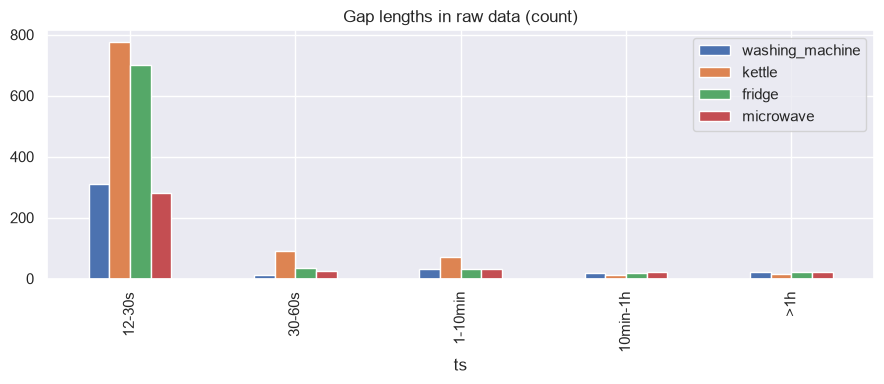

In [3]:
# Graph: gap lengths before filling
bins = [12, 30, 60, 600, 3600, np.inf]; labs = ["12-30s", "30-60s", "1-10min", "10min-1h", ">1h"]
gc = {a: pd.cut(raw[a].index.to_series().diff().dt.total_seconds().dropna(), bins, labels=labs).value_counts().reindex(labs)
      for a in APPS}
pd.DataFrame(gc).plot.bar(figsize=(9, 4), title="Gap lengths in raw data (count)"); plt.tight_layout()
plt.savefig("../data/fig_gaps.png", dpi=120); plt.show()

## 3.3 Glitch clipping (99.99th percentile) - before vs after

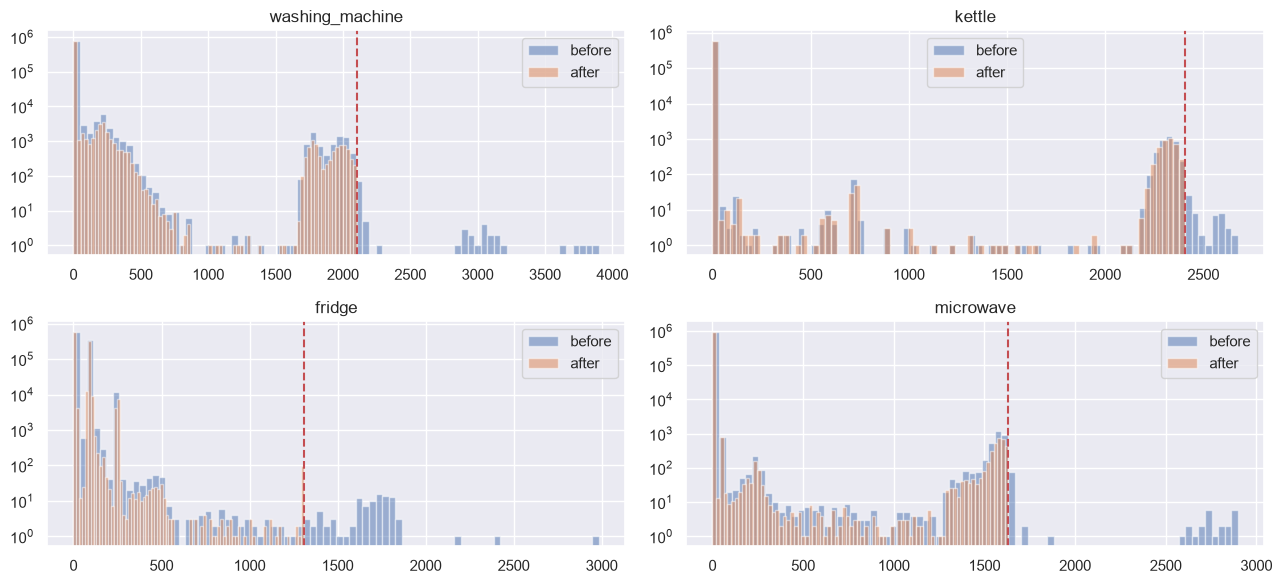

In [4]:
fig, ax = plt.subplots(2, 2, figsize=(13, 6))
for a_, a in zip(ax.ravel(), APPS):
    g = clean[a]; a_.hist(g.power_raw, bins=80, alpha=.5, label="before"); a_.hist(g.power, bins=80, alpha=.5, label="after")
    a_.set_yscale("log"); a_.axvline(stats[a]["clip_W"], c="r", ls="--"); a_.set_title(a); a_.legend()
plt.tight_layout(); plt.savefig("../data/fig_clipping.png", dpi=120); plt.show()

## 3.4 Smoothing - raw vs 5-point moving average (zoom on the highest-power event)

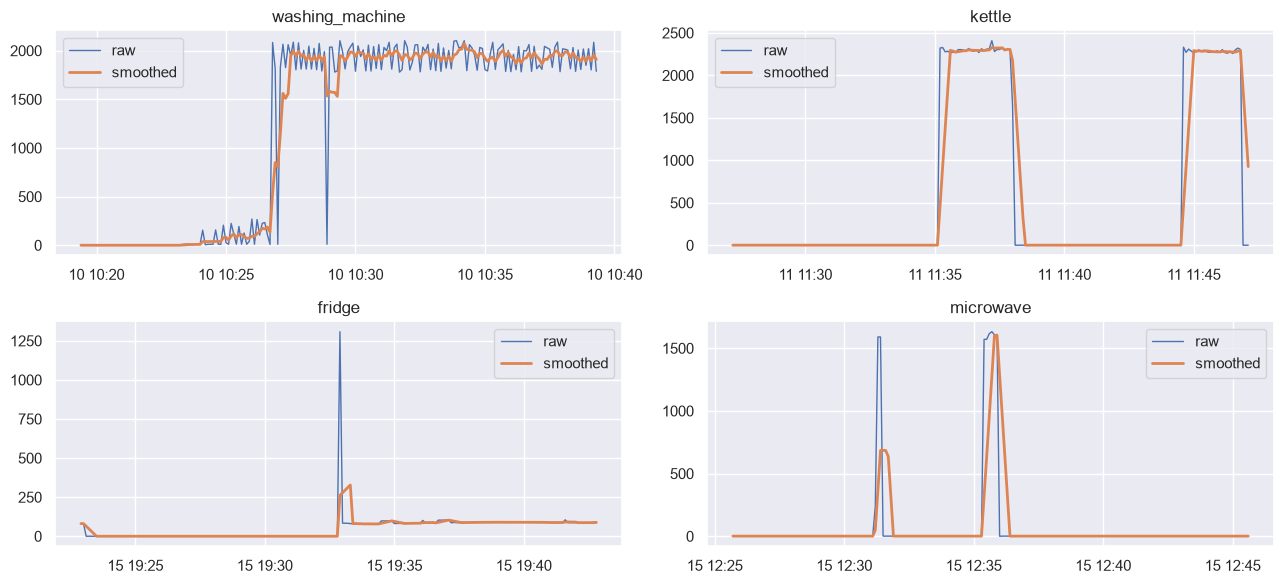

In [5]:
fig, ax = plt.subplots(2, 2, figsize=(13, 6))
for a_, a in zip(ax.ravel(), APPS):
    g = clean[a]; i = int(np.argmax(g.power.values)); w = g.iloc[max(0, i - 100): i + 100]
    a_.plot(w.index, w.power, label="raw", lw=1); a_.plot(w.index, w.power_smooth, label="smoothed", lw=2); a_.set_title(a); a_.legend()
plt.tight_layout(); plt.savefig("../data/fig_smoothing.png", dpi=120); plt.show()

## 3.5 Features: power and delta (change since previous reading)

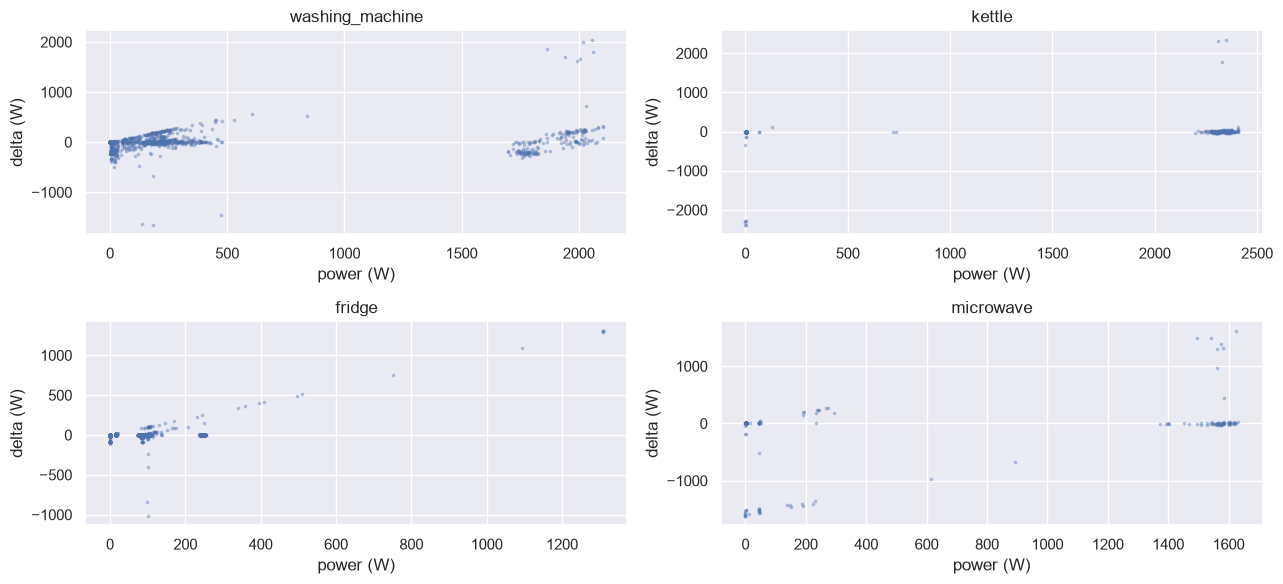

In [6]:
fig, ax = plt.subplots(2, 2, figsize=(13, 6))
for a_, a in zip(ax.ravel(), APPS):
    s = clean[a].sample(min(20000, len(clean[a])), random_state=SEED); a_.scatter(s.power, s.delta, s=3, alpha=.3)
    a_.set_title(a); a_.set_xlabel("power (W)"); a_.set_ylabel("delta (W)")
plt.tight_layout(); plt.savefig("../data/fig_features.png", dpi=120); plt.show()

## 3.6 ON-state filter - we train only on readings where the appliance is running

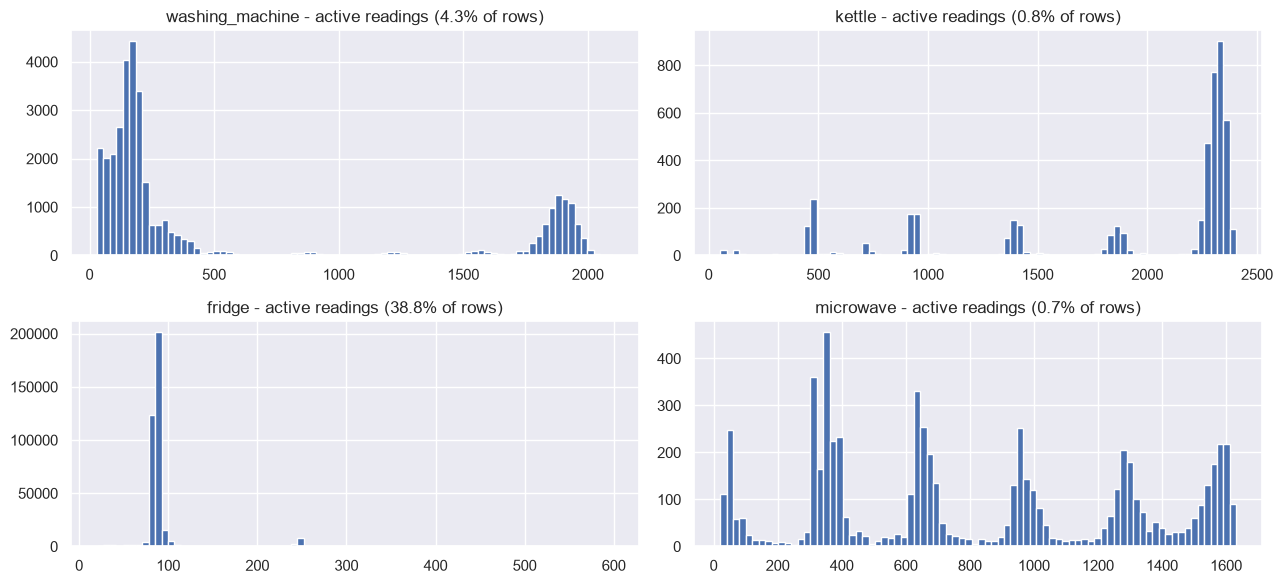

In [7]:
fig, ax = plt.subplots(2, 2, figsize=(13, 6))
for a_, a in zip(ax.ravel(), APPS):
    g = clean[a]; a_.hist(g.power_smooth[g.active], bins=80); a_.set_title(f"{a} - active readings ({g.active.mean()*100:.1f}% of rows)")
plt.tight_layout(); plt.savefig("../data/fig_active.png", dpi=120); plt.show()

## 3.7 Chronological 80/20 split and scaling (scaler fitted on TRAIN only)

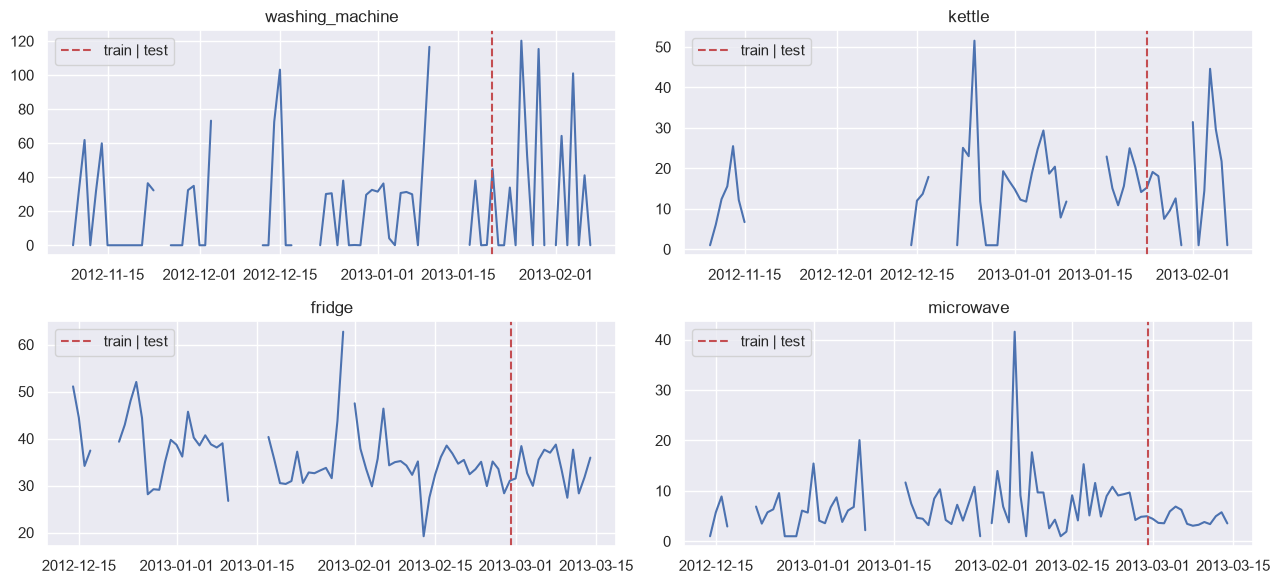

washing_machine train active rows: 25600 mean/std: [ 5.311e+02 -1.000e-01] [715.8 246.9]
kettle train active rows: 3814 mean/std: [1.8631e+03 6.0000e-01] [899.9 669.9]
fridge train active rows: 301180 mean/std: [91.6 -0.1] [38.5 36.2]
microwave train active rows: 5662 mean/std: [ 8.225e+02 -5.000e-01] [751.6 710.5]
saved cleaned CSVs to ../data


In [8]:
fig, ax = plt.subplots(2, 2, figsize=(13, 6))
for a_, a in zip(ax.ravel(), APPS):
    g = clean[a]; daily = g.power.resample("1D").mean(); a_.plot(daily.index, daily.values)
    a_.axvline(g.index[int(len(g) * .8)], c="r", ls="--", label="train | test"); a_.set_title(a); a_.legend()
plt.tight_layout(); plt.savefig("../data/fig_split.png", dpi=120); plt.show()
for a in APPS:
    g = clean[a]; tr = g[(g.split == "train") & g.active]; sc = StandardScaler().fit(tr[["power", "delta"]])
    print(a, "train active rows:", len(tr), "mean/std:", sc.mean_.round(1), sc.scale_.round(1))
    g.to_csv(f"../data/{a}_clean.csv", float_format="%.2f")
print("saved cleaned CSVs to ../data")